# 03 · Results and figures

Final picture after the review layer: 165 skills that Armenian employers ask
for, compared against what AUA's CSE and CBE syllabi document. Runs from
`results/skill_coverage.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
COLORS = {"COVERED": "#2d7a4f", "PARTIAL": "#d68910", "MISSING": "#b03a2e"}
ORDER = ["COVERED", "PARTIAL", "MISSING"]

df = pd.read_csv("../results/skill_coverage.csv")
FIG = "../results/figures/"

## Headline numbers

In [2]:
model = df.model_status.value_counts().reindex(["COVERED", "MISSING"])
final = df.final_status.value_counts().reindex(ORDER)
weighted = df.groupby("final_status").n_jobs.sum().reindex(ORDER) / df.n_jobs.sum()

print(f"model-based (binary):  {model['COVERED']} covered / {model['MISSING']} missing  "
      f"-> {model['COVERED'] / len(df):.1%} coverage")
print(f"after review (3-class): {final['COVERED']} covered / {final['PARTIAL']} partial / {final['MISSING']} missing")
print(f"share of job-skill mentions: " + ", ".join(f"{s.lower()} {weighted[s]:.1%}" for s in ORDER))

table = pd.crosstab(df.domain, df.final_status)[ORDER]
table["covered or partial"] = ((table.COVERED + table.PARTIAL) / table.sum(axis=1) * 100).round(1).astype(str) + "%"
table

model-based (binary):  106 covered / 59 missing  -> 64.2% coverage
after review (3-class): 97 covered / 39 partial / 29 missing
share of job-skill mentions: covered 59.8%, partial 14.2%, missing 26.0%


final_status,COVERED,PARTIAL,MISSING,covered or partial
domain,,,,
CBE,70,12,10,89.1%
CSE,27,27,19,74.0%


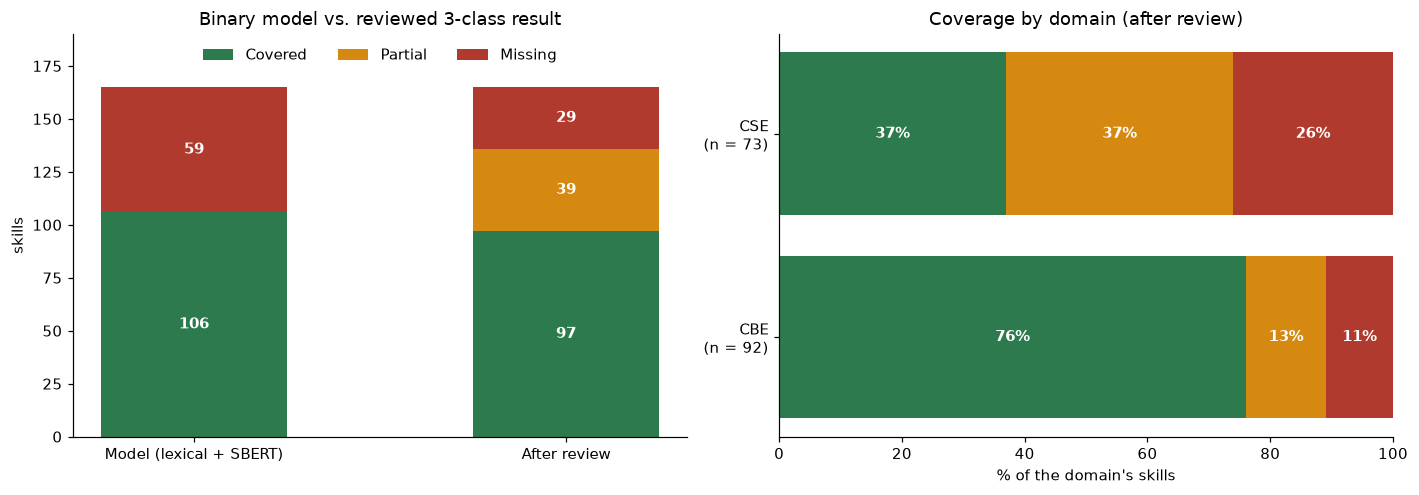

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
x = np.arange(2)
stacks = {"COVERED": [model["COVERED"], final["COVERED"]], "PARTIAL": [0, final["PARTIAL"]],
          "MISSING": [model["MISSING"], final["MISSING"]]}
bottom = np.zeros(2)
for s in ORDER:
    ax.bar(x, stacks[s], 0.5, bottom=bottom, color=COLORS[s], label=s.title())
    for xi, (b, v) in enumerate(zip(bottom, stacks[s])):
        if v:
            ax.text(xi, b + v / 2, str(v), ha="center", va="center", color="white", fontweight="bold")
    bottom += stacks[s]
ax.set_xticks(x, ["Model (lexical + SBERT)", "After review"])
ax.set(ylabel="skills", ylim=(0, 190), title="Binary model vs. reviewed 3-class result")
ax.legend(frameon=False, loc="upper center", ncol=3)

ax = axes[1]
shares = pd.crosstab(df.domain, df.final_status, normalize="index")[ORDER] * 100
left = np.zeros(len(shares))
for s in ORDER:
    ax.barh(shares.index, shares[s], left=left, color=COLORS[s], label=s.title())
    for yi, (l, v) in enumerate(zip(left, shares[s])):
        ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += shares[s]
counts = df.domain.value_counts()
ax.set_yticks(range(len(shares)), [f"{d}\n(n = {counts[d]})" for d in shares.index])
ax.set(xlabel="% of the domain's skills", xlim=(0, 100), title="Coverage by domain (after review)")

plt.tight_layout()
plt.savefig(FIG + "coverage_overview.png")
plt.show()

CBE looks well aligned: 70 of 92 skills covered outright. CSE has a much lower
strict coverage (27 of 73), but a large share is *partial*. Many CSE skills are
specific tools (a framework, a cloud platform) where the syllabus teaches the
underlying concept under a different name or not at all at tool level.

## Where the gaps are

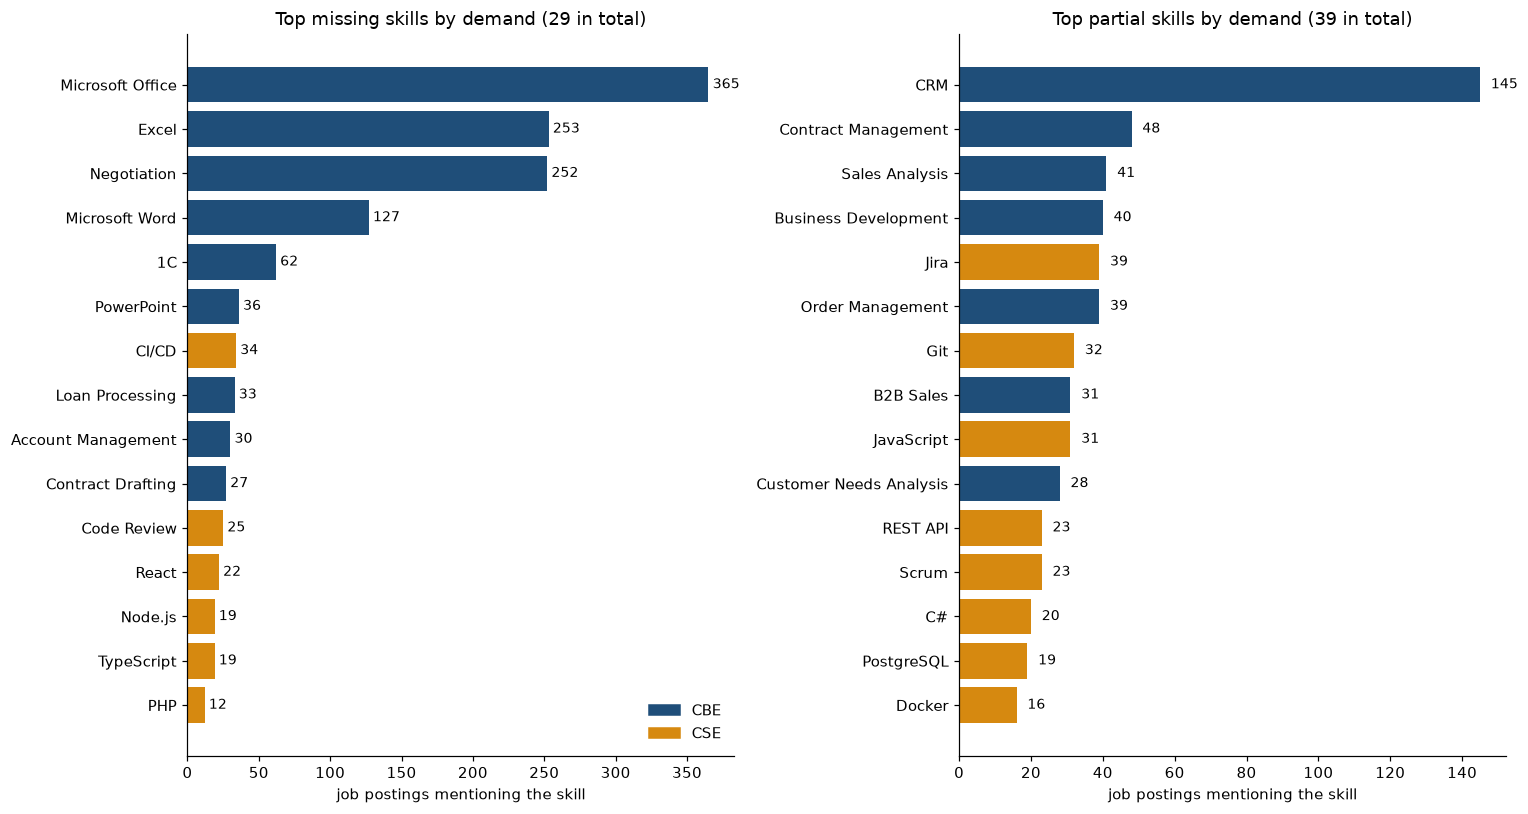

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, status in zip(axes, ["MISSING", "PARTIAL"]):
    sub = df[df.final_status == status].nlargest(15, "n_jobs").sort_values("n_jobs")
    colors = ["#1f4e79" if d == "CBE" else "#d68910" for d in sub.domain]
    ax.barh(sub.skill, sub.n_jobs, color=colors)
    for y, v in enumerate(sub.n_jobs):
        ax.text(v + 3, y, str(v), va="center", fontsize=9)
    ax.set(xlabel="job postings mentioning the skill",
           title=f"Top {status.lower()} skills by demand ({(df.final_status == status).sum()} in total)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#1f4e79", "#d68910"]]
axes[0].legend(handles, ["CBE", "CSE"], frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG + "top_gaps.png")
plt.show()

In [5]:
missing = df[df.final_status == "MISSING"].nlargest(12, "n_jobs")
missing[["skill", "domain", "n_jobs", "pct_of_postings", "similarity_score"]]

,skill,domain,n_jobs,pct_of_postings,similarity_score
0,Microsoft Office,CBE,365,22.7,0.4614
1,Excel,CBE,253,15.7,0.4911
2,Negotiation,CBE,252,15.7,0.4818
6,Microsoft Word,CBE,127,7.9,0.4356
17,1C,CBE,62,3.9,0.3622
42,PowerPoint,CBE,36,2.2,0.4098
45,CI/CD,CSE,34,2.1,0.3499
47,Loan Processing,CBE,33,2.0,0.4900
57,Account Management,CBE,30,1.9,0.6180
61,Contract Drafting,CBE,27,1.7,0.4326


The most-demanded missing skills are everyday workplace tools (Microsoft
Office, Excel, Word) and negotiation. These are probably used in courses but
never named in a syllabus, which is a documentation problem as much as a
teaching one. The CSE gaps are more concrete: specific frameworks, DevOps
tooling, and platforms that employers name explicitly.

## Demand vs. similarity

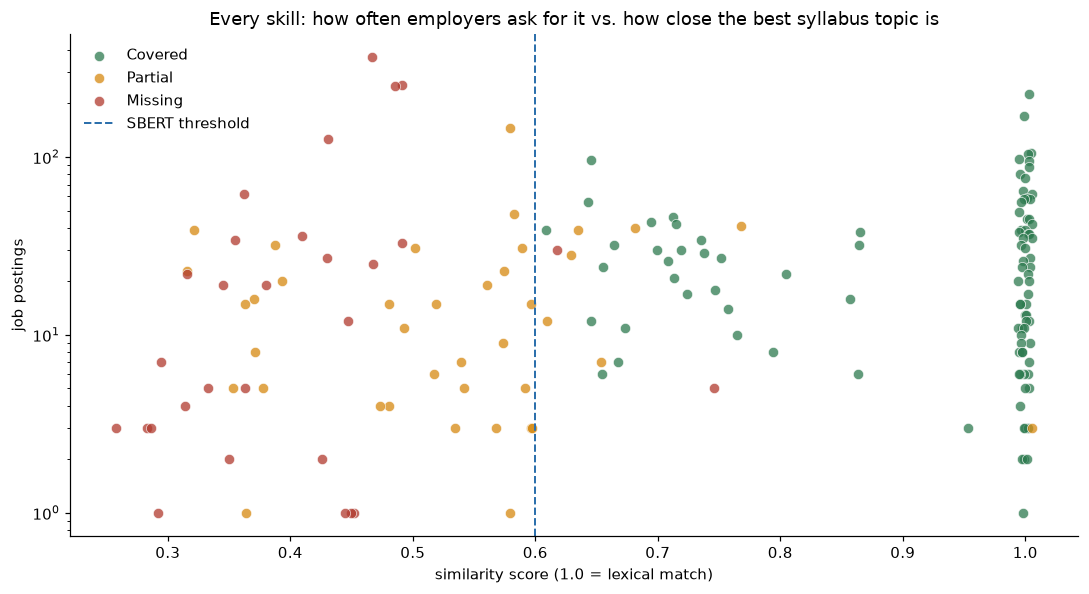

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
rng = np.random.default_rng(42)
for s in ORDER:
    sub = df[df.final_status == s]
    jitter = rng.uniform(-0.006, 0.006, len(sub))
    ax.scatter(sub.similarity_score + jitter, sub.n_jobs, s=45, alpha=0.75, color=COLORS[s],
               edgecolor="white", lw=0.5, label=s.title())
ax.axvline(0.60, color="#2C6FAC", ls="--", lw=1.3, label="SBERT threshold")
ax.set(xlabel="similarity score (1.0 = lexical match)", ylabel="job postings", yscale="log",
       title="Every skill: how often employers ask for it vs. how close the best syllabus topic is")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG + "demand_vs_similarity.png")
plt.show()

Partial and missing skills overlap heavily in the 0.45–0.60 band, which is
where the binary model can't make the call on its own. That overlap is the
case for the review layer.